# TSP restringido — Fuerza bruta

Enumeración exhaustiva de las rutas factibles (`route[2]==2`) y selección del mínimo coste.
Baseline **clásico exacto** (óptimo de referencia para el resto de solvers).


In [1]:
import itertools
import json
import math
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np


In [2]:
nodes = [0, 1, 2, 3, 4]
origin = 0
d02 = 4
dist = {
    (0, 1): 3, (0, 2): d02, (0, 3): 4, (0, 4): 2,
    (1, 2): 3, (1, 3): 4, (2, 3): 1, (2, 4): 6,
}
for (i, j), value in list(dist.items()):
    dist[(j, i)] = value
BIG_M = 100

def edge_exists(i, j):
    return (i, j) in dist

def cost(i, j):
    if i == j:
        return BIG_M
    return dist.get((i, j), BIG_M)

def route_cost(route):
    return sum(cost(route[i], route[i + 1]) for i in range(len(route) - 1))

def is_valid_route(route):
    if route[0] != origin or route[-1] != origin:
        return False
    if sorted(route[1:-1]) != [1, 2, 3, 4]:
        return False
    return route[2] == 2

def generate_candidate_routes():
    candidates = []
    for perm in itertools.permutations([1, 2, 3, 4]):
        route = [origin] + list(perm) + [origin]
        if is_valid_route(route):
            candidates.append({
                "route": route,
                "cost": route_cost(route),
                "uses_invalid_edges": any(not edge_exists(route[i], route[i + 1]) for i in range(len(route) - 1)),
            })
    return candidates

candidates = generate_candidate_routes()
OPTIMAL = min((c for c in candidates if not c["uses_invalid_edges"]), key=lambda c: c["cost"])
OPTIMAL_COST = float(OPTIMAL["cost"])
print("Candidatas:", len(candidates), "| óptimo estricto:", OPTIMAL)

def resolve_metrics_dir() -> Path:
    for base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        root = base / "Notebooks" / "Optimization" / "TSPOptimization"
        if root.is_dir():
            d = root / "metrics"
            d.mkdir(parents=True, exist_ok=True)
            return d
    d = Path.cwd().resolve() / "Notebooks" / "Optimization" / "TSPOptimization" / "metrics"
    d.mkdir(parents=True, exist_ok=True)
    return d

def save_tsp_metrics(payload: dict, filename: str):
    path = resolve_metrics_dir() / filename
    path.write_text(json.dumps(payload, indent=2))
    print("Saved:", path)
    return path


Candidatas: 6 | óptimo estricto: {'route': [0, 4, 2, 3, 1, 0], 'cost': 16, 'uses_invalid_edges': False}


## Resolución


In [3]:
N_RUNS = 1  # determinista
t0 = time.perf_counter()
feasible = [c for c in candidates if not c["uses_invalid_edges"]]
sol = min(feasible, key=lambda c: c["cost"])
elapsed = time.perf_counter() - t0

print("Solución:", sol["route"], "coste =", sol["cost"])
print(f"Tiempo: {elapsed:.6f}s | rutas evaluadas: {len(candidates)}")

payload = {
    "problem": "tsp",
    "solver": "brute_force",
    "family": "classical",
    "protocol": {"n_runs": N_RUNS, "method": "enumerate_feasible_routes"},
    "instance": {"nodes": nodes, "origin": origin, "d02": d02},
    "quality": {
        "optimal_cost": OPTIMAL_COST,
        "optimal_route": OPTIMAL["route"],
        "cost_mean": float(sol["cost"]),
        "cost_best": float(sol["cost"]),
        "gap_mean": float(sol["cost"] - OPTIMAL_COST),
    },
    "success_rate": 1.0,
    "time_s": {"mean": float(elapsed), "std": 0.0, "total": float(elapsed)},
    "effort": {"routes_evaluated": len(candidates), "energy_evals_mean": len(candidates)},
    "runs": [{"seed": 0, "cost": float(sol["cost"]), "route": sol["route"], "success": True, "time_s": float(elapsed)}],
}
save_tsp_metrics(payload, "bruteforce_tsp.json")


Solución: [0, 4, 2, 3, 1, 0] coste = 16
Tiempo: 0.000059s | rutas evaluadas: 6
Saved: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/TSPOptimization/metrics/bruteforce_tsp.json


PosixPath('/Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/TSPOptimization/metrics/bruteforce_tsp.json')

## Storytelling plots

Figuras para documento/slides → `figures/`.


Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/TSPOptimization/figures/instance_tsp_graph.png


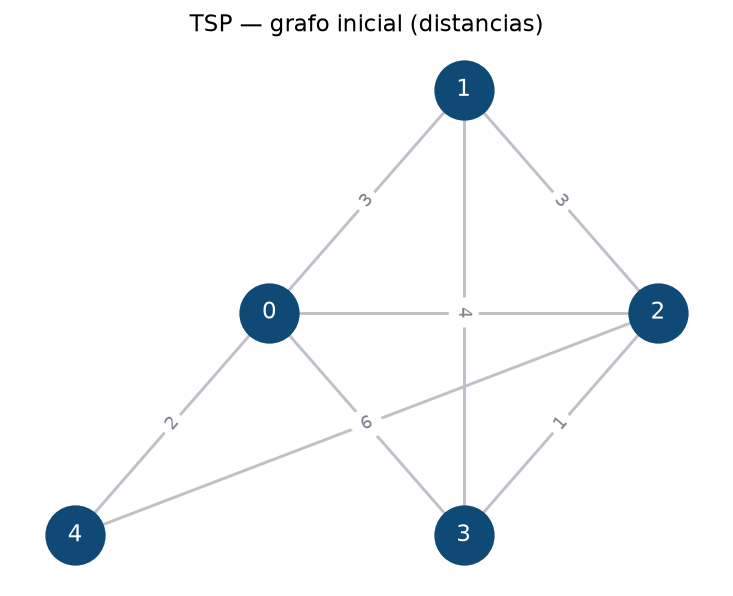

Saved figure: /Users/juanprada/Documents/UNIR-MasterQC-QuantumAdvantageInDataScience/Notebooks/Optimization/TSPOptimization/figures/bruteforce_tsp_route.png


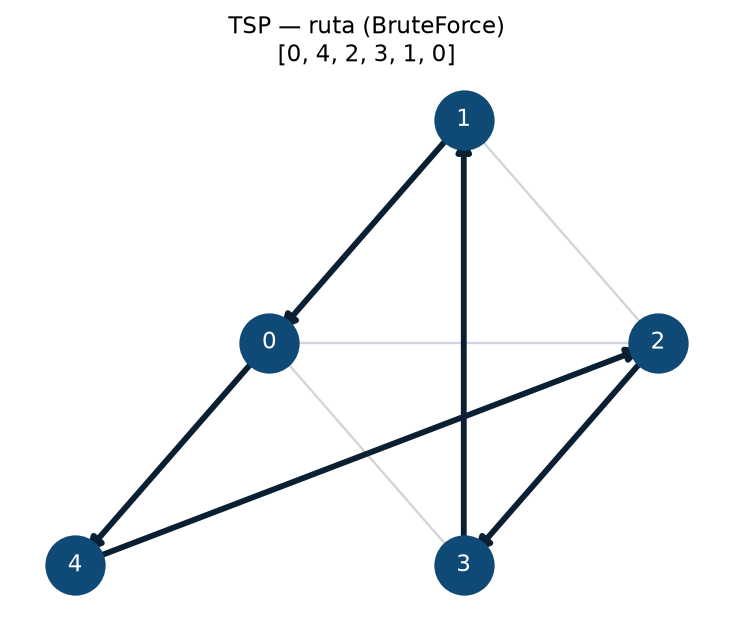

In [4]:
# --- storytelling plots (auto) ---
from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

for _base in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    _lib = _base / "Notebooks" / "lib"
    if (_lib / "storytelling.py").is_file():
        _s = str(_lib)
        if _s not in sys.path:
            sys.path.insert(0, _s)
        break
else:
    raise FileNotFoundError("Notebooks/lib/storytelling.py not found")

import importlib
import storytelling as _storytelling
importlib.reload(_storytelling)
from storytelling import (
    resolve_figures_dir,
    plot_tsp_instance, plot_tsp_route,
)

figures_dir = resolve_figures_dir("Optimization", "TSPOptimization")
plot_tsp_instance(nodes, dist, figures_dir, stem="instance")
# ruta del solver: payload runs o sol
_route = None
if "payload" in globals() and payload.get("runs"):
    _runs = [r for r in payload["runs"] if r.get("route") is not None]
    if _runs:
        _route = min(_runs, key=lambda r: float(r.get("cost", 1e18))).get("route")
if _route is None and "sol" in globals():
    _route = sol["route"] if isinstance(sol, dict) else sol
if _route is None and "OPTIMAL" in globals():
    _route = OPTIMAL.get("route")
if _route is None:
    raise RuntimeError("No TSP route found for storytelling plot")
plot_tsp_route(nodes, dist, _route, figures_dir, stem="bruteforce", title="BruteForce")

plt.show()
